# Projet Leyenda - Livrable 1
##### *Par Noah.V, Noah.M, Hugo.L*

## **Contexte:**
L'entreprise TouNum est une entreprise qui travaille sur la numérisation de différents type de documents. Ils essayent de moderniser leur architecture pour le tri automatique de documents due au grand nombre de documents fourni par les clients. Faisant appel à nous pour determiner le captionning des images avec légendes de manière automatiques. Nous remarquons deux contraintes, la première est la qualité des images qui diffère par exemple entre chaque image, et trié automatiquement si c'est une photo ou d'autres types de documents.

Le workflow demandé par l'entreprise devra suivre ce modèle la:

![Image demandé](src/workflow.png)

Le projet sera divisé en trois partie:
- La première sera de contrsuire un CNN via des datasets d'images pré étiqueté
- Le deuxième sera d'améliorer la clarté et l'enlever les différents bruits ou flou des images
- Le troisème sera de créer un réseau de neurones qui génère des légendes pour des photographies

Nous avons déjà réalisé le premier livrable avec différentes architectures, mais aussi différentes résolutions et comme on a pu le voir dans ce précédent livrable, les images redimensionné peuvent avoir du bruit ou être floue. C'est pour cela que dans ce ***deuxième livrable***, le but sera d'améliorer la clarté de ses images et permettre au modèle de mieux comprendre les images pour une meilleure detection.

Détail du ***Livrable 2:***
- Le code de chargement du fichier
- Le code du débruitage sur un sous-ensemble d'images bruitées. Le code doit être accompagné d'explications.
- Une étude de cas.

## Importation des librairies

In [1]:
%pip install -r requirements.txt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import plotly.express as px
from DL_dataset import *
from plotly.subplots import make_subplots
import plotly.graph_objects as go

Note: you may need to restart the kernel to use updated packages.


## Etape 1 : Chargement des images

Pour charger les differentes images de ce livrable 2, comme au livrable 1. Nous avons crée un script relier à *DL_datatset.py* qui a pour but de télécharger et préprocess les images automatiquements. Ensuite nous chargons les images dans les deux datasets train et test.

### Téléchargement du dataset

In [2]:
folder_raw = Path(f"./data")

if not os.path.exists(folder_raw):
    step_DL, step_unzip = True, True
    os.makedirs(folder_raw)
elif Path(folder_raw).exists() and len(os.listdir(folder_raw)) == 0:
    step_DL, step_unzip = True, True
else:
    step_DL, step_unzip = False, False

urls=[
    "https://drive.google.com/file/d/1Cp-x-Sc7wUzipu1GysZXx9g4Y2jrpIka/view?usp=sharing",
]

if step_DL==True:
    print("File download:")
    for link in urls:
        download_file(link,folder_raw)

if step_unzip==True:
    Get_file(folder_raw)

### Chargements des variables et Hyperparametres.

Ses différentes valeurs seront utilisés tout au long de ce notebook pour les models.

In [3]:
BATCH_SIZE = 16
IMG_SIZE = (256,256) 
train_split = 0.8
test_split = 0.2 
EPOCHS=200
noise_value= 0.1 #valeur pour definir l'ajout du bruit plus c'est grand, plus c'est un bruit fort
dataset_raw = Path(f"./data/dataset/")



### Répartition des images

Due aux nombres limités d'images disponibles, nous décidons de partir sur une répartition 80/20.

In [4]:

train_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=1 - train_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="training",
    seed=42
)

test_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=test_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="validation",
    seed=42
)



Found 148 files.
Using 119 files for training.
Found 148 files.
Using 29 files for validation.


In [ ]:
def train_preprocess(image):
    image = image / 255.0
    actual_batch_size = tf.shape(image)[0]
    dynamic_patch_size = tf.stack([actual_batch_size, 128, 128, 3])
    image = tf.image.random_crop(image, size=dynamic_patch_size)
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)

    noise = tf.random.normal(shape=tf.shape(image), mean=0.0, stddev=noise_value)
    noisy_image = tf.clip_by_value(image + noise, 0.0, 1.0)
    return noisy_image,image

def val_preprocess(image):

    image = image / 255.0
    image = tf.image.resize(image, [128, 128])

    noise = tf.random.normal(shape=tf.shape(image), mean=0.0, stddev=noise_value)
    noisy_image = tf.clip_by_value(image + noise, 0.0, 1.0)

    return noisy_image,image



AUTOTUNE = tf.data.experimental.AUTOTUNE
train_set = train_set.map(train_preprocess, num_parallel_calls=AUTOTUNE)
test_set = test_set.map(val_preprocess, num_parallel_calls=AUTOTUNE)

train_set = train_set.prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

### Affichage des images

Pour confirmer le chargement des images et que les images ont bien été séparé entre le *test set* et le *train set*.

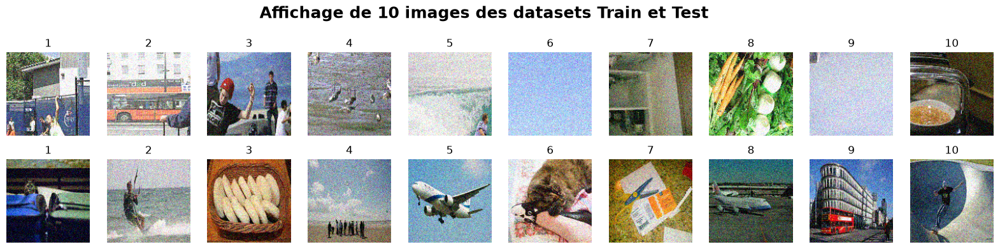

In [6]:
n = 10

#Affichage partie Trai,
plt.figure(figsize=(20, 4))
for images, _ in train_set.take(1):
    for i in range(n):
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(f'{i+1}')
        plt.axis("off")

#Affichage partie Test
for images, _ in test_set.take(1):
    for i in range(n):
        ax = plt.subplot(2, n, i + 1+n)
        plt.title("Image dans le set de Test")
        plt.imshow(images[i].numpy())
        plt.title(f'{i+1}')
        plt.axis("off") 

plt.suptitle("Affichage de 10 images des datasets Train et Test", fontsize=18, fontweight='bold', y=1.05)
plt.show() 

## Etape 2 : Présentation de notre modele retenu

### DAE : Denoising Auto Encodeur

On initialise le modele via un DAE qui est un type d'autoencoder spécialisé pour le débruitement des images.
L'objectif principal d'un DAE est d'apprendre une représentation (image bruité) d'un ensemble de données, généralement dans le but de réduire la dimensionnalité, en introduisant une contrainte de reconstruction (le bruit). Il fonctionne de cette façon :

![Image DAE](src/Dae_architecture.png)

De plus notre architecture ajoute au début lors de la gestion de l'image, nous divisons l'images en sous image sans changer la taille de celle ci car cela permettra au modèle de pouvoir géneré plus d'images et se focus sur les détails pour un résultats moins flou et plus proche de la réalité.

In [7]:
"""
Input
"""

input_img = Input(shape=(128, 128, 3))

"""
Partie encodage
"""

x = Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same')(input_img)
x = MaxPooling2D(pool_size=(2, 2), padding='same')(x)

x = Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same')(x)
encoded = MaxPooling2D(pool_size=(2, 2), padding='same')(x)

"""
Partie Décodage
"""

x = Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same')(encoded)
x = UpSampling2D(size=(2, 2))(x)

x = Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same')(x)
x = UpSampling2D(size=(2, 2))(x)

"""
Output
"""

decoded = Conv2D(filters=3, kernel_size=(3, 3), activation='sigmoid', padding='same')(x)


In [8]:
autoencoder = Model(inputs=input_img, outputs=decoded)
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', 
        patience=15, 
        restore_best_weights=True 
    )

history = autoencoder.fit(
    train_set,
    epochs=EPOCHS,
    validation_data=test_set,
    callbacks=[early_stop]
)

Epoch 1/200


c:\Users\Noah\Documents\GitHub\Cnn-and-RNN\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 167ms/step - loss: 0.0695 - val_loss: 0.0487
Epoch 2/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step - loss: 0.0400 - val_loss: 0.0304
Epoch 3/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step - loss: 0.0330 - val_loss: 0.0249
Epoch 4/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step - loss: 0.0258 - val_loss: 0.0273
Epoch 5/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - loss: 0.0247 - val_loss: 0.0229
Epoch 6/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step - loss: 0.0204 - val_loss: 0.0246
Epoch 7/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step - loss: 0.0191 - val_loss: 0.0199
Epoch 8/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step - loss: 0.0188 - val_loss: 0.0135
Epoch 9/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0158 - val_loss: 0.0129
Epoch 10/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - loss: 0.0148 - val_loss: 0.0112
Epoch 11/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - loss: 0.0111 - val_loss: 0.0104
Epoch 12/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0121 - val_lo

### Sauvegarde du modèle

In [10]:
if not os.path.exists("Model"):
    os.makedirs("Model")
autoencoder.save(f"Model/DAE_noise_{noise_value}.keras")

### Affichage comparaison entre l'image d'origine, bruité et débruité

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step


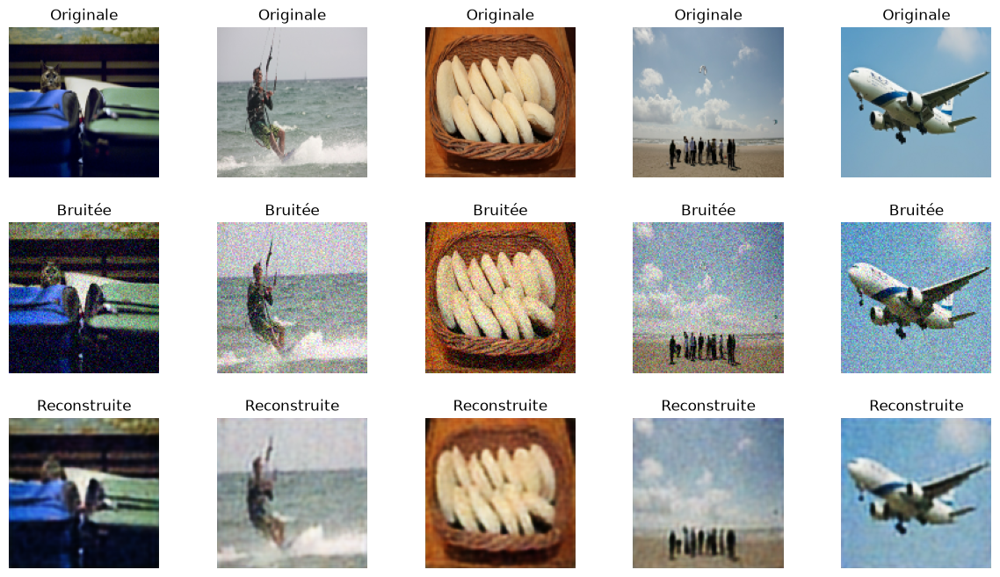

In [11]:
test_batch_noisy, test_batch_clean = next(iter(test_set.take(1)))
decoded_imgs = autoencoder.predict(test_batch_noisy)

n = min(5, BATCH_SIZE)  

plt.figure(figsize=(15, 8))
for i in range(n):
    # Original (clean)
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(test_batch_clean[i].numpy())
    plt.title("Originale")
    plt.axis('off')

    # Noisy
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(test_batch_noisy[i].numpy())
    plt.title("Bruitée")
    plt.axis('off')

    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(decoded_imgs[i])
    plt.title("Reconstruite")
    plt.axis('off')

plt.subplots_adjust(wspace=0.1, hspace=0.3)
plt.show()

Comparaison avec un noise de 0.3

Found 148 files.
Using 119 files for training.


Found 148 files.
Using 29 files for validation.


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 177ms/step - loss: 0.0611 - val_loss: 0.0141
Epoch 2/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0193 - val_loss: 0.0182
Epoch 3/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0133 - val_loss: 0.0122
Epoch 4/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0126 - val_loss: 0.0089
Epoch 5/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step - loss: 0.0096 - val_loss: 0.0085
Epoch 6/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0095 - val_loss: 0.0077
Epoch 7/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0078 - val_loss: 0.0076
Epoch 8/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0082 - val_loss: 0.0072
Epoch 9/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - loss: 0.0082 - val_loss: 0.0071
Epoch 10/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - loss: 0.0066 - val_loss: 0.0070
Epoch 11/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0076 - val_loss: 0.0069
Epoch 12/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 121ms/step - loss: 0.0

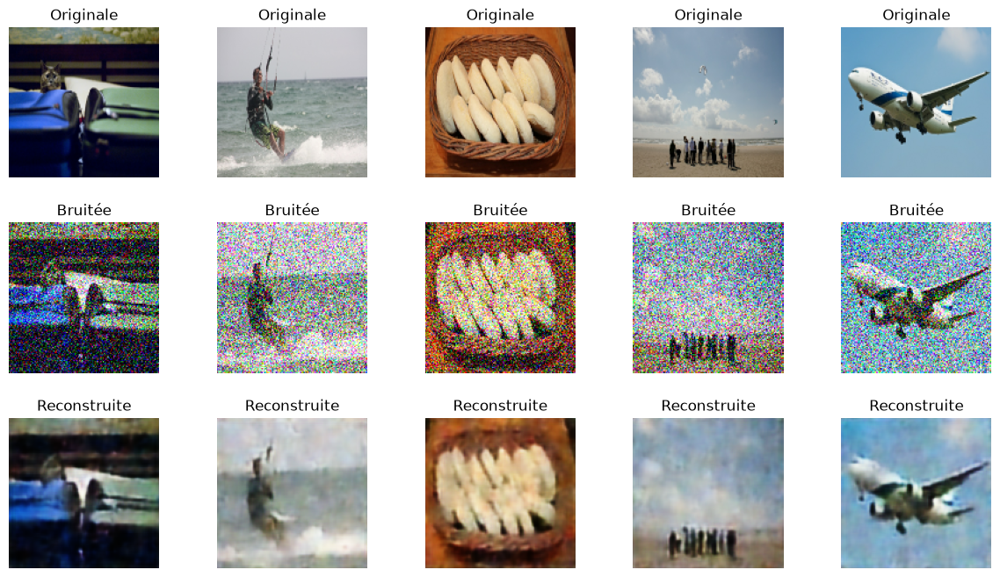

In [12]:
noise_value=0.3
train_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=1 - train_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="training",
    seed=42
)

test_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=test_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="validation",
    seed=42
)
AUTOTUNE = tf.data.experimental.AUTOTUNE

train_set = train_set.map(train_preprocess, num_parallel_calls=AUTOTUNE)
test_set = test_set.map(val_preprocess, num_parallel_calls=AUTOTUNE)

train_set = train_set.prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

Dae = Model(inputs=input_img, outputs=decoded)
Dae.compile(optimizer='adam', loss='mse')
Dae.summary()

early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', 
        patience=15, 
        restore_best_weights=True 
    )

history = Dae.fit(
    train_set,
    epochs=EPOCHS,
    validation_data=test_set,
    callbacks=[early_stop]
)

if not os.path.exists("Model"):
    os.makedirs("Model")
Dae.save(f"Model/DAE_noise_{noise_value}.keras")

test_batch_noisy, test_batch_clean = next(iter(test_set.take(1)))
decoded_imgs = Dae.predict(test_batch_noisy)

n = min(5, BATCH_SIZE)  

plt.figure(figsize=(15, 8))
for i in range(n):
    # Original (clean)
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(test_batch_clean[i].numpy())
    plt.title("Originale")
    plt.axis('off')

    # Noisy
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(test_batch_noisy[i].numpy())
    plt.title("Bruitée")
    plt.axis('off')

    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(decoded_imgs[i])
    plt.title("Reconstruite")
    plt.axis('off')

plt.subplots_adjust(wspace=0.1, hspace=0.3)
plt.show()

Found 148 files.


Using 119 files for training.
Found 148 files.
Using 29 files for validation.


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 153ms/step - loss: 0.0311 - val_loss: 0.0178
Epoch 2/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.0144 - val_loss: 0.0108
Epoch 3/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - loss: 0.0124 - val_loss: 0.0098
Epoch 4/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0100 - val_loss: 0.0090
Epoch 5/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0102 - val_loss: 0.0089
Epoch 6/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - loss: 0.0084 - val_loss: 0.0086
Epoch 7/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0094 - val_loss: 0.0084
Epoch 8/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - loss: 0.0092 - val_loss: 0.0083
Epoch 9/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0098 - val_loss: 0.0085
Epoch 10/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step - loss: 0.0088 - val_loss: 0.0083
Epoch 11/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 105ms/step - loss: 0.0091 - val_loss: 0.0082
Epoch 12/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.0

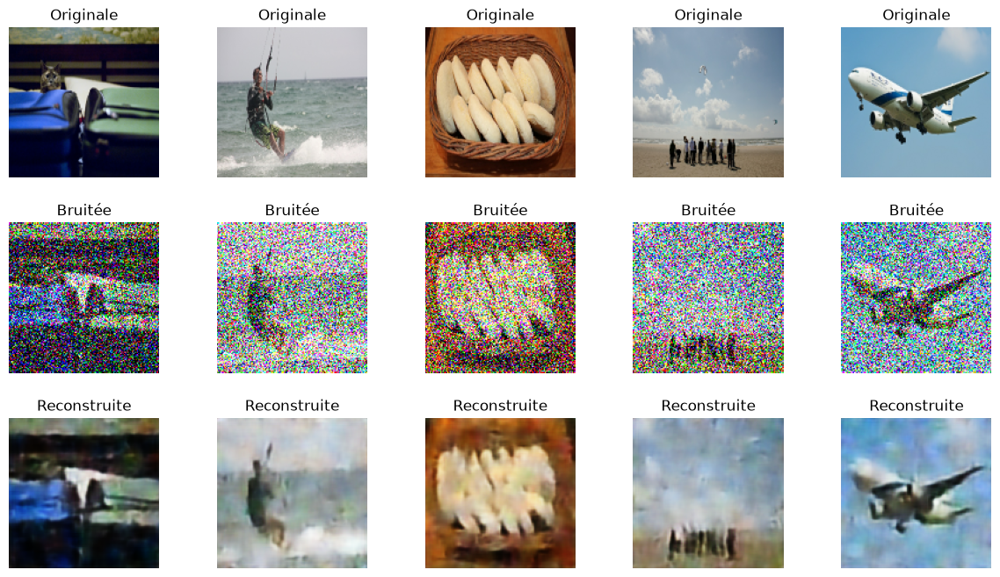

In [13]:
noise_value=0.5
train_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=1 - train_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="training",
    seed=42
)

test_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=test_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="validation",
    seed=42
)
AUTOTUNE = tf.data.experimental.AUTOTUNE

train_set = train_set.map(train_preprocess, num_parallel_calls=AUTOTUNE)
test_set = test_set.map(val_preprocess, num_parallel_calls=AUTOTUNE)

train_set = train_set.prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

Dae = Model(inputs=input_img, outputs=decoded)
Dae.compile(optimizer='adam', loss='mse')
Dae.summary()

early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', 
        patience=15, 
        restore_best_weights=True 
    )

history = Dae.fit(
    train_set,
    epochs=EPOCHS,
    validation_data=test_set,
    callbacks=[early_stop]
)

if not os.path.exists("Model"):
    os.makedirs("Model")
Dae.save(f"Model/DAE_noise_{noise_value}.keras")

test_batch_noisy, test_batch_clean = next(iter(test_set.take(1)))
decoded_imgs = Dae.predict(test_batch_noisy)

n = min(5, BATCH_SIZE)  

plt.figure(figsize=(15, 8))
for i in range(n):
    # Original (clean)
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(test_batch_clean[i].numpy())
    plt.title("Originale")
    plt.axis('off')

    # Noisy
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(test_batch_noisy[i].numpy())
    plt.title("Bruitée")
    plt.axis('off')

    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(decoded_imgs[i])
    plt.title("Reconstruite")
    plt.axis('off')

plt.subplots_adjust(wspace=0.1, hspace=0.3)
plt.show()

Found 148 files.
Using 119 files for training.


Found 148 files.
Using 29 files for validation.


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 152ms/step - loss: 0.0239 - val_loss: 0.0204
Epoch 2/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step - loss: 0.0184 - val_loss: 0.0126
Epoch 3/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 158ms/step - loss: 0.0142 - val_loss: 0.0140
Epoch 4/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - loss: 0.0140 - val_loss: 0.0111
Epoch 5/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0108 - val_loss: 0.0109
Epoch 6/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0111 - val_loss: 0.0104
Epoch 7/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 159ms/step - loss: 0.0103 - val_loss: 0.0103
Epoch 8/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 120ms/step - loss: 0.0113 - val_loss: 0.0101
Epoch 9/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - loss: 0.0106 - val_loss: 0.0101
Epoch 10/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.0103 - val_loss: 0.0100
Epoch 11/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 0.0102 - val_loss: 0.0100
Epoch 12/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - loss: 0.0

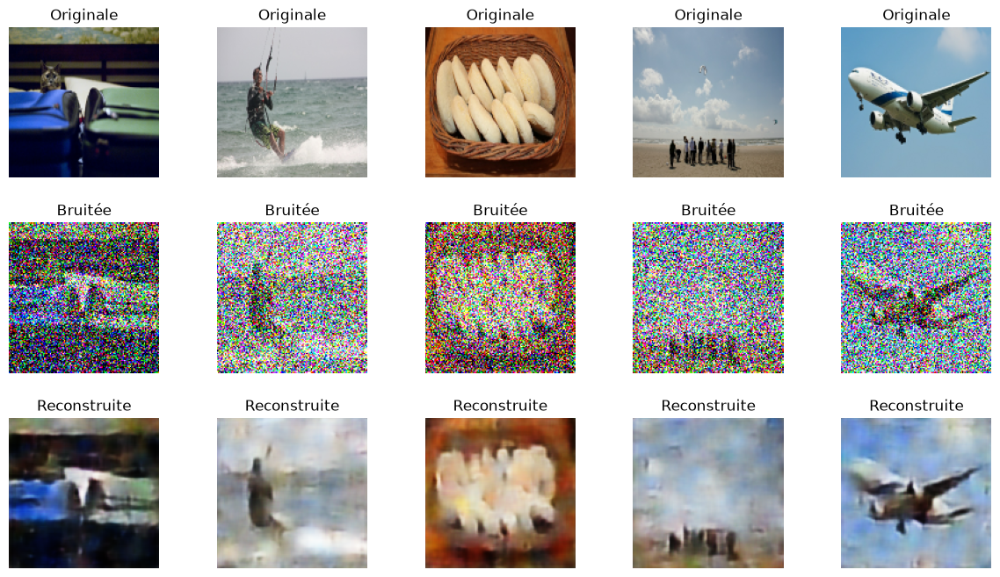

In [14]:
noise_value=0.7
train_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=1 - train_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="training",
    seed=42
)

test_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=test_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="validation",
    seed=42
)
AUTOTUNE = tf.data.experimental.AUTOTUNE

train_set = train_set.map(train_preprocess, num_parallel_calls=AUTOTUNE)
test_set = test_set.map(val_preprocess, num_parallel_calls=AUTOTUNE)

train_set = train_set.prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

Dae = Model(inputs=input_img, outputs=decoded)
Dae.compile(optimizer='adam', loss='mse')
Dae.summary()

early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', 
        patience=15, 
        restore_best_weights=True 
    )

history = Dae.fit(
    train_set,
    epochs=EPOCHS,
    validation_data=test_set,
    callbacks=[early_stop]
)

if not os.path.exists("Model"):
    os.makedirs("Model")
Dae.save(f"Model/DAE_noise_{noise_value}.keras")

test_batch_noisy, test_batch_clean = next(iter(test_set.take(1)))
decoded_imgs = Dae.predict(test_batch_noisy)

n = min(5, BATCH_SIZE)  

plt.figure(figsize=(15, 8))
for i in range(n):
    # Original (clean)
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(test_batch_clean[i].numpy())
    plt.title("Originale")
    plt.axis('off')

    # Noisy
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(test_batch_noisy[i].numpy())
    plt.title("Bruitée")
    plt.axis('off')

    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(decoded_imgs[i])
    plt.title("Reconstruite")
    plt.axis('off')

plt.subplots_adjust(wspace=0.1, hspace=0.3)
plt.show()

Comme on peut le voir avec nos différentes valeures de bruit appliqué sur les images. Plus le bruit est fort, plus le DAE a du mal a restructurer les images, on voit que à 0.1, l'image est la plus proche de celle réelle, à 0.3, celle ci est proche même si légérement plus flou que celle a 0.1, mais pour le bruit à 0.5 et 0.7, sont semblablement similaire avec cette effet de flou dessus, mais un résultat quand même correcte car on voit que le modele arrive un petit peu à replacer les elements et couleurs au bon endroit. En terme de Loss value, nos 4 modéles ont tous des résultats plutot interessant et l'on voit que ses derniers restructurent assez bien l'image. Comme expliqué plus haut, le patch permet cette valeur aussi faible car sinon sans cette méthode et uniquement la data augmentation, on avait pu voir des modéles moins performants et des résultats moins cohérents.

# Etape 3 : Etude de cas 

## Comparaisson des différents modèles utilisés 

Pour ce projet, nous avons essayé d'utiliser plusieurs auto encoder differents, comme l'auto-encoder traditionnel, le VAE, le DAE, CVAE...
Cependant plusieurs d'entre eux avaient des résultats qu'ils nous convenaient pas ou avaient des contraintes trop importantes pour être sélectionné. Comme l'auto encoder traditionnel qui...

### AE : Auto Encodeur

Pour commencer, nous avons implémenté un autoencodeur simple à l’aide de la bibliothèque TensorFlow. Un autoencodeur est un réseau de neurones dont l’objectif est d’apprendre à reconstruire une image à partir d’une représentation compressée de celle-ci.

Le modèle est composé de deux parties principales : l’encodeur et le décodeur. L’encodeur transforme l’image d’entrée en une représentation compacte appelée espace latent, qui contient les informations essentielles de l’image sous la forme d’un vecteur de dimension réduite. Le décodeur utilise ensuite cette représentation pour reconstruire l’image d’origine.

Pendant l’entraînement, le modèle apprend à minimiser la différence entre l’image d’entrée et l’image reconstruite. L’objectif est ainsi d’obtenir une représentation compacte qui conserve suffisamment d’informations pour permettre une reconstruction aussi fidèle que possible à l’image initiale.

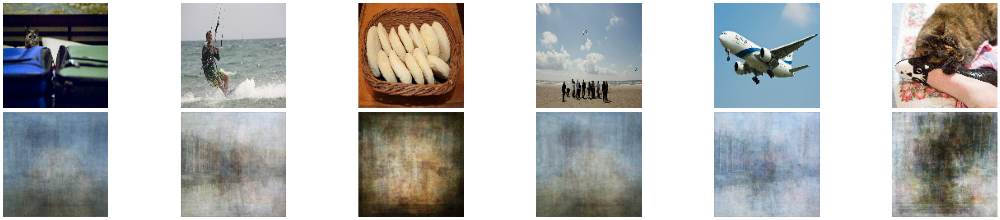
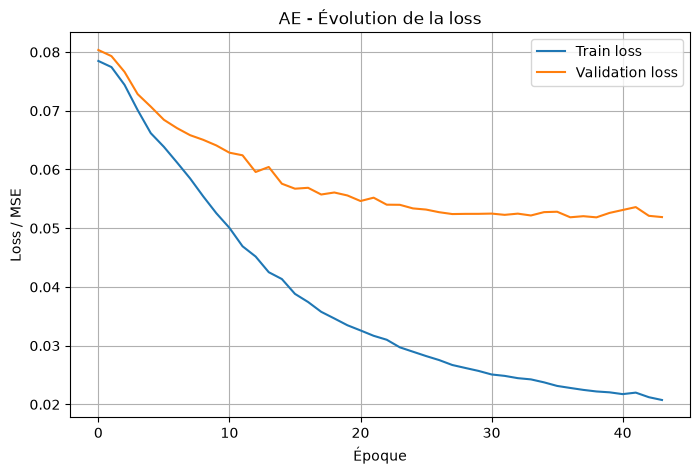

### VAE : Auto Encodeur Variationnel

Nous avons testé le modèle d'auto-encodeur variationnel (VAE). Il consiste à remplacer l'espace latent par une distribution latente. Il est composé de μ (mu), de σ (sigma, que l'on manipule souvent sous la forme du log de la variance) et de ε (epsilon). L'étape de sampling combine ces trois éléments pour tirer un point de la distribution latente : 

z=μ+σ×ε. 

Les valeurs de μ et de σ sont calculées à partir de la représentation cachée de l'image par l'encodeur, tandis que ε est tiré aléatoirement dans une loi gaussienne centrée réduite :

N(0,1).

Nous présenterons les résultats plus bas, mais nous n'avons pas obtenu de bons résultats avec ce modèle. Nous sommes d'abord restés bloqués dans le phénomène de posterior collapse. Il se produit lorsque μ et le log de la variance tendent vers zéro : la distribution latente devient identique à la loi a priori, et le décodeur ignore l'entrée. Le modèle a alors tendance à produire une image moyenne, la même en sortie quelle que soit l'entrée.

Ce VAE est composé uniquement de couches Dense. Nous sommes parvenus à sortir du posterior collapse, mais le modèle souffre alors d'un fort surapprentissage : il reproduit correctement les images d'entraînement, mais pas celles de test, pour lesquelles les reconstructions n'ont aucun rapport avec l'entrée.

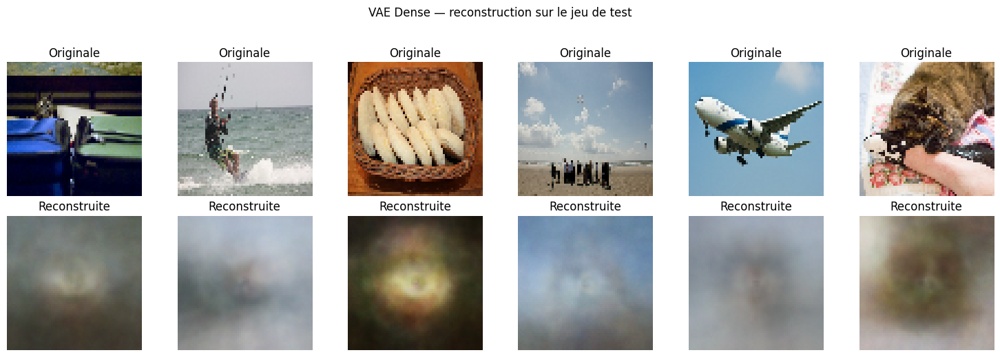
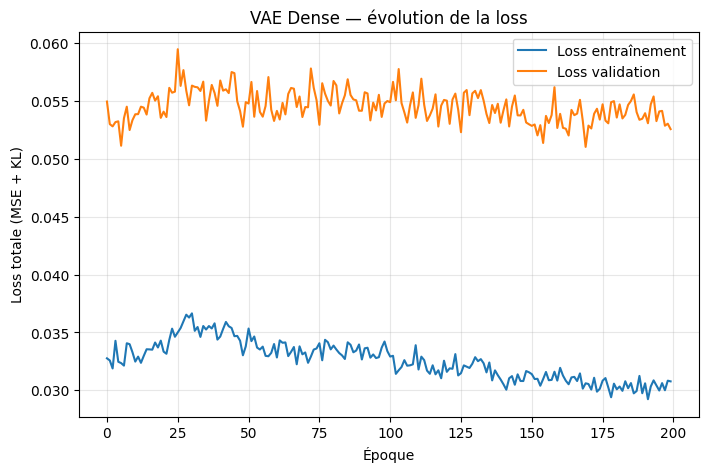

### CVAE : Auto Encodeur Variationnel Conditionnel

Ce modèle est similaire au VAE du point de vue des constructions mathématiques ; ce qui change, c'est le réseau de neurones utilisé à l'intérieur. Il est composé de couches de convolution, qui extraient les détails de l'image étape par étape, sans que toute l'image arrive d'un coup dans une seule couche. Comme dans un CNN, cela permet au CVAE d'apprendre la représentation petit à petit, des motifs simples (contours, couleurs) vers des formes plus complexes. Les filtres de convolution étant partagés sur toute l'image, le modèle utilise aussi moins de paramètres qu'un réseau uniquement composé de couches Dense.

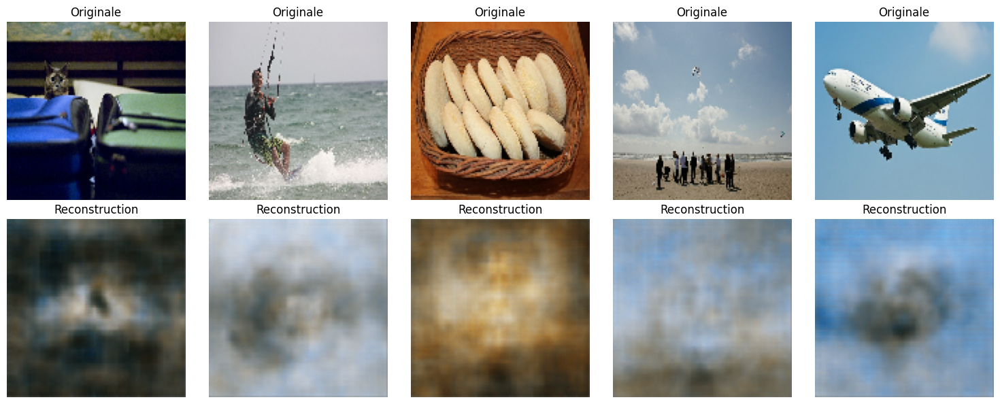
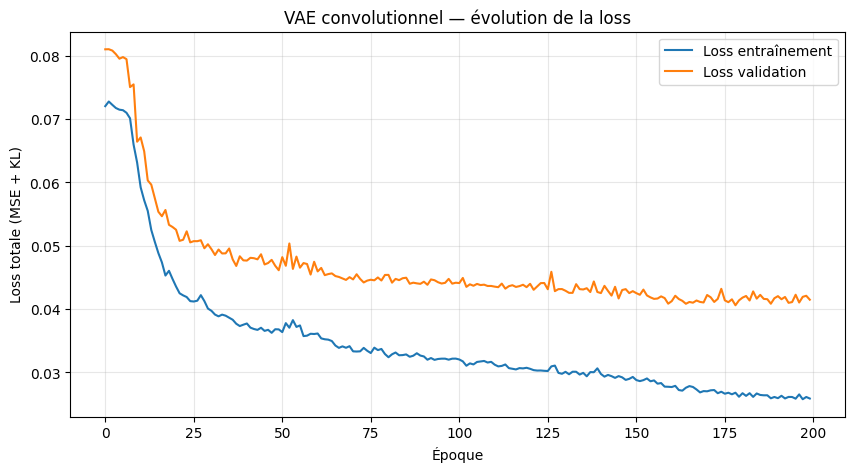

## DAE : Explication val loss

Comme expliqué plus haut dans l'étape 2, la *val loss* pour le DAE est très faible, ce qui explique que notre modèle arrive à bien reconstruire l'image d'origine avec les couleurs de celle ci et leurs teintes. Ce qui explique le choix de ce type d'auto encodeur face aux autres qu'on a pu testé et qui ont des résultats moins performant et une *Val loss* plus haute.

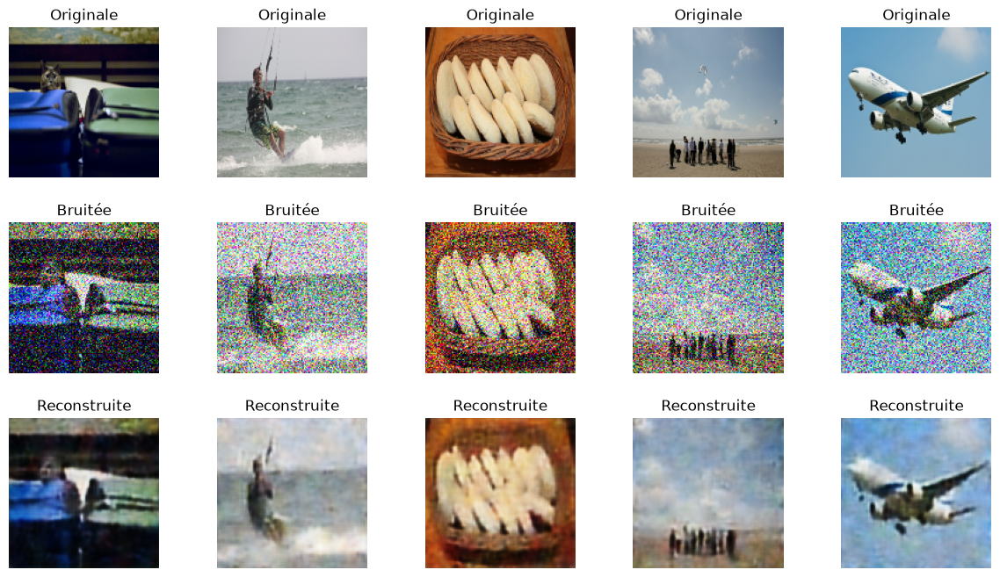

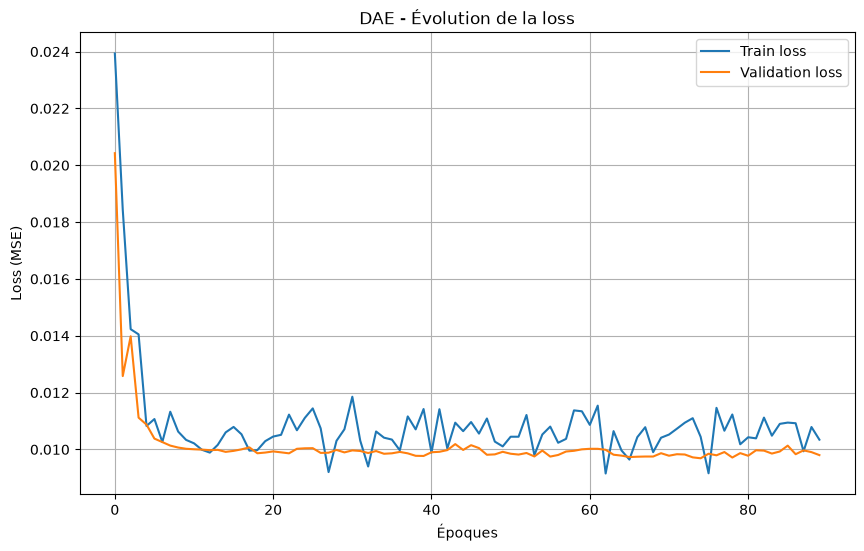

## Evaluation et vue d'ensemble des resultats des differents modeles